# FLUX.2 [Klein] — Accessory Edit Timing Test

Quick test on ONE image from the Popescu dataset (`generated_portraits_hashed_final`), adding each of our three accessories (baseball cap, glasses, face mask) one at a time, and measuring how long each edit takes.

Adapted from the working MAAD-Face generation notebook — same model, same pipeline call, same measured ~24.6s/image on an A100 from that earlier session.

**This notebook lives in the same Drive folder as:**
- `final_dataset.csv` (HASH, ETHNICITY, GENDER, AGE)
- `generated_portraits_hashed_final/` (images, named `<hash>.<ext>`)

Run on Colab with a GPU runtime (A100 recommended, same as before).

## 1. Setup

In [1]:
!pip install -q -U diffusers transformers accelerate huggingface_hub pandas

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 842.9/842.9 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 45.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.


In [2]:
import torch
print("GPU available:", torch.cuda.is_available())
print("GPU name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

GPU available: True
GPU name: NVIDIA A100-SXM4-40GB


## 2. Mount Drive and locate the dataset

Since this notebook lives in the same folder as `final_dataset.csv` and `generated_portraits_hashed_final/`, we just need to find that folder's path once Drive is mounted.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
import os

# Since the notebook lives in the same folder as the data, search Drive for
# whichever folder actually contains final_dataset.csv, instead of hardcoding a path.
DATASET_DIR = None
for root, dirs, files in os.walk("/content/drive/MyDrive"):
    if "final_dataset.csv" in files:
        DATASET_DIR = root
        break

if DATASET_DIR is None:
    raise FileNotFoundError("Could not find final_dataset.csv anywhere under /content/drive/MyDrive")

print(f"Found dataset folder: {DATASET_DIR}")

CSV_PATH = os.path.join(DATASET_DIR, "final_dataset.csv")
IMAGES_DIR = os.path.join(DATASET_DIR, "generated_portraits_hashed_final")

print("CSV exists:", os.path.exists(CSV_PATH))
print("Images dir exists:", os.path.exists(IMAGES_DIR))
if os.path.exists(IMAGES_DIR):
    sample_files = os.listdir(IMAGES_DIR)[:5]
    print("Sample filenames:", sample_files)

Found dataset folder: /content/drive/MyDrive/Frugal AI Project
CSV exists: True
Images dir exists: True
Sample filenames: ['generated_portraits_hashed']


## 3. Load the dataset list and pick ONE test image

In [7]:
import pandas as pd

df = pd.read_csv(CSV_PATH)
print(f"Loaded {len(df):,} rows")
df.head()

Loaded 9,000 rows


,HASH,ETHNICITY,GENDER,AGE
0,00d562183457ce02,African,Female,25
1,0138c6e4992e66bf,African,Female,25
2,0200880184f7bc70,African,Female,25
3,02ccc4dd9d55e5d5,African,Female,25
4,02f7f45434981436,African,Female,25


In [9]:
IMAGE_INDEX = 0  # which row to use as the test image, 0-based

test_row = df.iloc[IMAGE_INDEX]
test_hash = test_row["HASH"]
print(f"Selected: {test_hash} ({test_row['ETHNICITY']}, {test_row['GENDER']}, age {test_row['AGE']})")

import glob

# Images live in a subfolder inside IMAGES_DIR (generated_portraits_hashed_final/generated_portraits_hashed/...),
# so search recursively instead of assuming a flat folder.
matches = glob.glob(os.path.join(IMAGES_DIR, "**", f"{test_hash}*"), recursive=True)
if not matches:
    raise FileNotFoundError(f"No file found for hash {test_hash} anywhere under {IMAGES_DIR}")
source_path = matches[0]
print(f"File on disk: {source_path}")

Selected: 00d562183457ce02 (African, Female, age 25)
File on disk: /content/drive/MyDrive/Frugal AI Project/generated_portraits_hashed_final/generated_portraits_hashed/00d562183457ce02.jpg


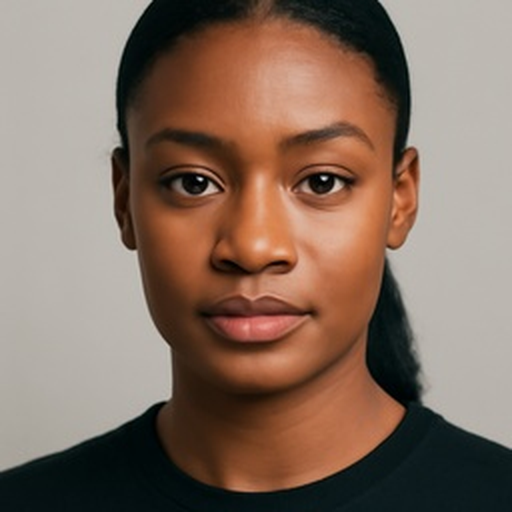

In [10]:
from PIL import Image, ImageOps

original_image = Image.open(source_path).convert("RGB")
target_size = 512
init_image = ImageOps.pad(
    original_image, (target_size, target_size),
    method=Image.LANCZOS, color=(255, 255, 255), centering=(0.5, 0.5),
)
init_image

## 4. Load FLUX.2 [Klein]

Same model and pipeline as the MAAD-Face notebook: `black-forest-labs/FLUX.2-klein-base-4B`.

In [11]:
from diffusers import Flux2KleinPipeline

pipe = Flux2KleinPipeline.from_pretrained(
    "black-forest-labs/FLUX.2-klein-base-4B",
    torch_dtype=torch.bfloat16,
)
pipe.enable_model_cpu_offload()
print("Pipeline loaded.")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/422 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 17 files:   0%|          | 0/17 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Pipeline loaded.


## 5. The three accessory tasks

Each is applied independently to the SAME source image. One task = one edit = one output file + one timing measurement.

NOTE: prompts below are a first pass, not final — refine wording once we look at the actual outputs (matches Popescu's own "basic prompt, to be refined" framing for the job-fitness prompt too).

In [12]:
TASKS = {
    "cap": "add a plain baseball cap on the head, keep everything else the same",
    "glasses": "add a pair of clear prescription eyeglasses, keep everything else the same",
    "mask": "add a white disposable face mask covering the nose and mouth, keep everything else the same",
}

## 6. Generate — one call per task, timed

In [13]:
import time

os.makedirs("generated", exist_ok=True)
results_log = []

for task_name, instruction in TASKS.items():
    t0 = time.time()
    result = pipe(
        image=init_image,
        prompt=instruction,
        guidance_scale=4.0,
        num_inference_steps=50,
        generator=torch.Generator(device="cuda").manual_seed(0),
    ).images[0]
    elapsed = time.time() - t0

    out_path = f"generated/{test_hash}_{task_name}.png"
    result.save(out_path)
    results_log.append({"task": task_name, "output": out_path, "seconds": elapsed})
    print(f"[{task_name}] {elapsed:.1f}s -> {out_path}")

print(f"\nDone. {len(results_log)} images generated for {test_hash}.")
total_time = sum(r["seconds"] for r in results_log)
avg_time = total_time / len(results_log)
print(f"Total time for this identity (3 accessories): {total_time:.1f}s")
print(f"Average time per edit: {avg_time:.1f}s")

  0%|          | 0/50 [00:00<?, ?it/s]

[cap] 29.6s -> generated/00d562183457ce02_cap.png


  0%|          | 0/50 [00:00<?, ?it/s]

[glasses] 25.2s -> generated/00d562183457ce02_glasses.png


  0%|          | 0/50 [00:00<?, ?it/s]

[mask] 25.3s -> generated/00d562183457ce02_mask.png

Done. 3 images generated for 00d562183457ce02.
Total time for this identity (3 accessories): 80.1s
Average time per edit: 26.7s


## 7. Visual check — source vs. all three results

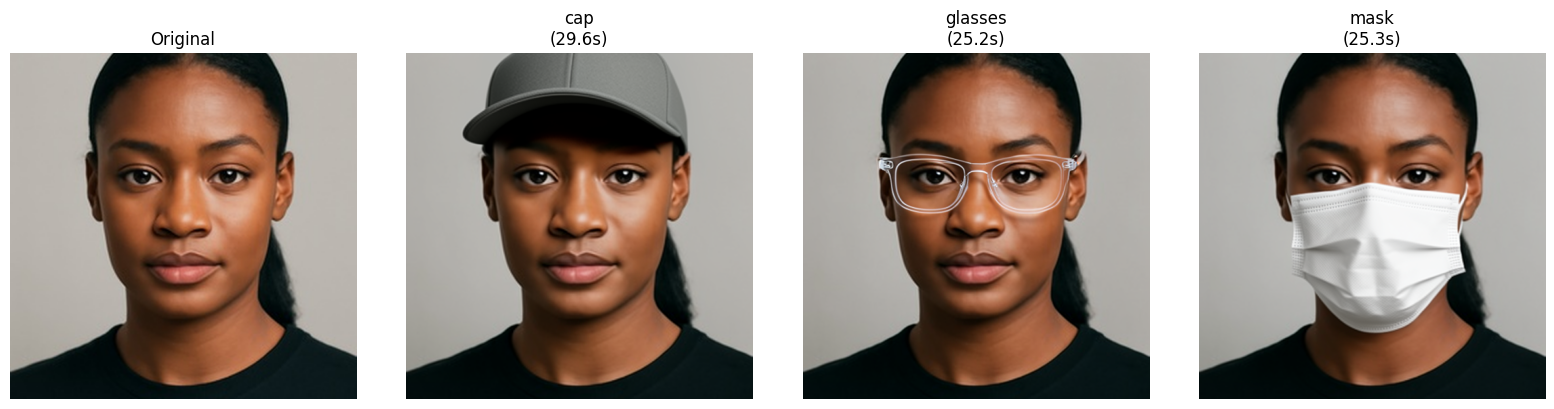

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(TASKS) + 1, figsize=(4 * (len(TASKS) + 1), 4))

axes[0].imshow(init_image)
axes[0].set_title("Original")
axes[0].axis("off")

for ax, r in zip(axes[1:], results_log):
    img = Image.open(r["output"])
    ax.imshow(img)
    ax.set_title(f"{r['task']}\n({r['seconds']:.1f}s)")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 8. Project the full run

Using the measured per-edit time from THIS run (not the old 24.6s figure, which was measured on a different dataset/task) to project the full 720-identity x 3-accessory batch (30 per demographic cell).

In [15]:
N_IDENTITIES = 720   # 30 per cell x 24 cells
N_ACCESSORIES = 3

total_edits = N_IDENTITIES * N_ACCESSORIES
projected_seconds = total_edits * avg_time
projected_hours = projected_seconds / 3600

print(f"Measured avg time per edit (this run): {avg_time:.2f}s")
print(f"Total edits for full batch: {total_edits:,}")
print(f"Projected total time: {projected_seconds:,.0f}s = {projected_hours:.2f} GPU-hours")

Measured avg time per edit (this run): 26.69s
Total edits for full batch: 2,160
Projected total time: 57,659s = 16.02 GPU-hours
